# 03 — Statistical baselines: rules, control charts and drift-adjusted scores

**Goal**: measure how far classical statistical monitoring goes on this problem, so that machine learning methods have a clear bar to clear.

**Key findings**

- The **expert rule** from notebook 01 (loaded ≥ 90% of the last 30 minutes) detects **4/4** failures with **1.25 false alarms per week**, but never early: it needs ~27 loaded minutes, so it fires 10–45 minutes after each reported start.
- The best statistical detector is a **robust z-score of the 2-hour mean oil temperature against a 7-day rolling reference**: **4/4 with 0.28 false alarms per week** (4 false alarms in 15 weeks, 2 of them during unreported leak-like episodes). Following the seasonal drift cuts false alarms fivefold compared with the same feature against a fixed training reference (1.38 per week).
- The **CUSUM chart on the motor current** is the only detector with a real early warning: **4/4, 0.64 false alarms per week, failure 4 flagged 12.9 h early**. Accumulating small deviations pays off when a leak develops slowly.
- **Multivariate distance scores fail** (1–2/4 detected): the max robust z-score and Hotelling T² over the 18 features are dominated by one heavy-tailed feature (`reservoirs_min_2h`, z ≈ 300 in normal operation), which pushes the threshold far above the failure signal.
- **Parameters matter**: the EWMA chart on the motor current detects 2/4 with the textbook λ = 0.05, but 4/4 with λ = 0.01–0.02. CUSUM is stable for k between 0.25 and 1.
- **Bar for machine learning**: 4/4 detected with fewer than 0.3 false alarms per week, and early warning on failure 4.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

from metrobench import baselines as bl
from metrobench import evaluation as ev
from metrobench.data import FAILURES, failure_mask, load, sustained_load_episodes
from metrobench.features import load_features
from metrobench.plotstyle import FAILURE, GAP, INK_MUTED, SERIES, shade_failures, use_style

use_style()
FIG, RESULTS = Path("docs/figures"), Path("results")
RESULTS.mkdir(exist_ok=True)
grid, X = load_features()
X_train, _ = ev.split(X)
grid_train, _ = ev.split(grid)
episodes = sustained_load_episodes(load())
unreported = episodes[~episodes.reported]

## 1. Detectors

All parameters are textbook defaults fixed before looking at the test period: λ = 0.05 for EWMA (a memory of roughly 2/λ = 40 minutes, about two compressor cycles) and k = 0.5σ for CUSUM (tuned to detect shifts of about one standard deviation). Every reference statistic is estimated on the training period.

| Detector | Input | Idea |
|---|---|---|
| Sustained-load rule | `load_share_30min` | the leak signature from notebook 01: loaded ≥ 90% of the last 30 min. Evaluated with the expert threshold 0.9 and with the calibrated threshold |
| Max robust \|z\| | 18 window features | standardise each feature (training median and MAD), alarm on the most extreme one |
| Hotelling T² | 18 window features | squared Mahalanobis distance to the training mean; accounts for correlations between features |
| EWMA chart | minute load share, minute motor current | exponentially weighted mean, standardised by its in-control deviation |
| CUSUM chart | minute load share, minute motor current | cumulative sum of standardised deviations above k; accumulates evidence of a sustained shift |
| Rolling-baseline z | `oil_mean_2h`, `current_mean_2h`, `load_share_2h` | robust z-score against the previous 7 days instead of the fixed training period, to follow slow drift |

In [2]:
scores = {
    "Sustained-load rule (expert, 0.9)": X.load_share_30min,
    "Sustained-load rule (calibrated)": X.load_share_30min,
    "Max robust |z| (18 features)": bl.max_abs_zscore(X, X_train),
    "Hotelling T² (18 features)": bl.hotelling_t2(X, X_train),
    "EWMA, load share": bl.ewma_chart(grid.DV_eletric, grid_train.DV_eletric, lam=0.05),
    "EWMA, motor current": bl.ewma_chart(grid.Motor_current, grid_train.Motor_current, lam=0.05),
    "CUSUM, load share": bl.cusum(grid.DV_eletric, grid_train.DV_eletric, k=0.5),
    "CUSUM, motor current": bl.cusum(grid.Motor_current, grid_train.Motor_current, k=0.5),
    "Rolling-baseline z, oil 2 h": bl.rolling_baseline_zscore(X.oil_mean_2h),
    "Rolling-baseline z, current 2 h": bl.rolling_baseline_zscore(X.current_mean_2h),
    "Rolling-baseline z, load share 2 h": bl.rolling_baseline_zscore(X.load_share_2h),
}
results = ev.summarize(scores, fixed_thresholds={"Sustained-load rule (expert, 0.9)": 0.9}, unreported=unreported)
results.to_csv(RESULTS / "03_statistical.csv")

## 2. Results on the test period

Calibrated threshold (≤ 1 alarm per week on training data). Lead times in hours, positive = before the reported start. *Best at budget* is the optimistic result with the best threshold at ≤ 1 false alarm per week on the test period (n/a: no threshold stays within the budget).

In [3]:
view = results.copy()
view["detected"] = view["detected"].astype(int).astype(str) + "/4"
view["best at budget"] = (view["best_detected"].astype(int).astype(str) + "/4").where(view["best_false_alarms_per_week"].notna(), "n/a")
view = view.rename(columns={f"lead_h_{i}": f"lead F{i} (h)" for i in FAILURES.index} | {
    "false_alarms_per_week": "false alarms / week", "time_in_alarm_%": "time in alarm (%)",
    "false_alarms_in_unreported": "of which unreported episodes"})
cols = ["detected", "lead F1 (h)", "lead F2 (h)", "lead F3 (h)", "lead F4 (h)", "false alarms / week",
        "of which unreported episodes", "time in alarm (%)", "best at budget"]
view[cols].round(2)

,detected,lead F1 (h),lead F2 (h),lead F3 (h),lead F4 (h),false alarms / week,of which unreported episodes,time in alarm (%),best at budget
detector,,,,,,,,,
"Sustained-load rule (expert, 0.9)",4/4,-0.77,-0.18,-0.25,-0.25,1.25,3,5.13,n/a
Sustained-load rule (calibrated),4/4,-0.77,-0.23,-0.30,-0.42,1.11,3,5.05,n/a
Max robust |z| (18 features),1/4,NaN,NaN,-35.28,NaN,1.04,0,0.42,0/4
Hotelling T² (18 features),2/4,NaN,NaN,-35.28,-0.40,0.97,1,1.06,2/4
"EWMA, load share",4/4,-0.95,-0.30,-0.37,-0.15,1.41,3,5.04,4/4
"EWMA, motor current",2/4,-4.93,NaN,NaN,-0.32,0.06,1,0.59,4/4
"CUSUM, load share",4/4,-0.82,-0.18,-0.25,11.28,1.09,3,6.47,4/4
"CUSUM, motor current",4/4,-1.63,-1.02,-1.13,12.88,0.64,3,7.54,4/4
"Rolling-baseline z, oil 2 h",4/4,-1.97,-1.33,-1.88,0.30,0.28,2,2.46,4/4


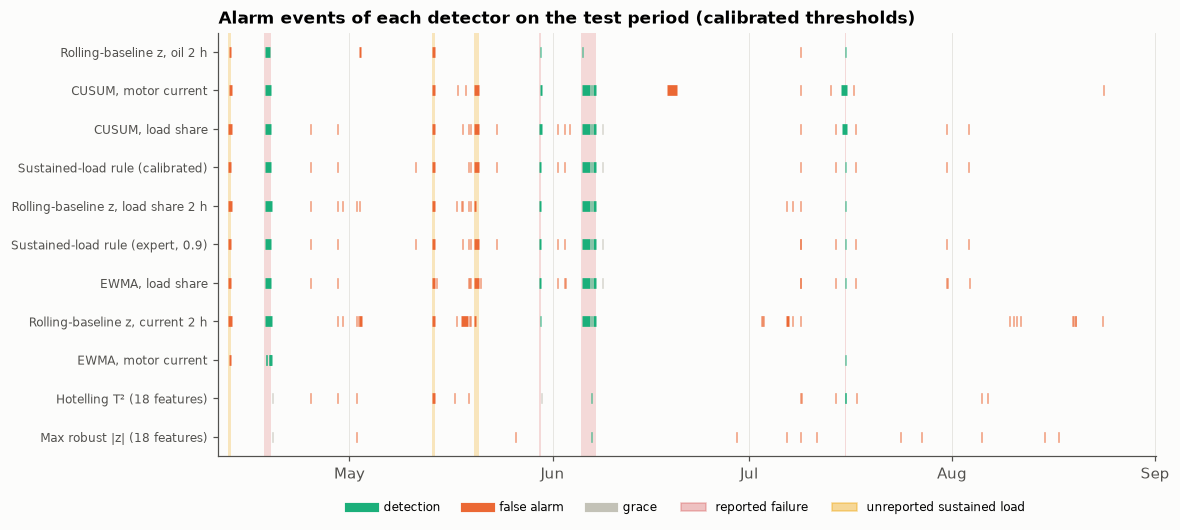

In [4]:
order = results.sort_values(["detected", "false_alarms_per_week"], ascending=[False, True]).index
_, test_period = ev.split(X)
fig, ax = plt.subplots(figsize=(11, 5))
for row, name in enumerate(order[::-1]):
    score_train, score_test = ev.split(scores[name])
    threshold = results.loc[name, "threshold"]
    events = ev.evaluate(score_test, threshold)["events"]
    for start, end, label in events[["start", "end", "label"]].itertuples(index=False):
        color = {"detection": SERIES[2], "grace": GAP, "false alarm": SERIES[1]}[label]
        ax.plot([start, max(end, start + pd.Timedelta("3h"))], [row, row], color=color, lw=7, solid_capstyle="butt")
shade_failures(ax, FAILURES, label=False)
for s, e in unreported[["start", "end"]].itertuples(index=False):
    if s >= ev.SPLIT:
        ax.axvspan(s, e, color=SERIES[3], alpha=0.25, lw=0)
ax.set_yticks(range(len(order)), order[::-1], fontsize=8)
ax.set_xlim(test_period.index.min(), test_period.index.max())
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], color=c, lw=6) for c in [SERIES[2], SERIES[1], GAP]] + \
          [plt.Rectangle((0, 0), 1, 1, color=FAILURE, alpha=0.3), plt.Rectangle((0, 0), 1, 1, color=SERIES[3], alpha=0.4)]
ax.legend(handles, ["detection", "false alarm", "grace", "reported failure", "unreported sustained load"],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=5, fontsize=8)
ax.set_title("Alarm events of each detector on the test period (calibrated thresholds)")
fig.savefig(FIG / "03_alarm_timeline.png")
plt.show()

Most detectors share the same alarms because they all measure the same thing, sustained load. Several of the shared false alarms coincide with the unreported sustained-load episodes of April 12, May 13 and May 19–20 (yellow), which no detector based on load can avoid. The rolling-baseline oil score is the quietest: it misses nothing and raises four false alarms in 15 weeks, two of them on unreported episodes. The two CUSUM charts are the only ones whose alarm on failure 4 starts ~12 hours before the reported window.

## 3. Why the multivariate scores fail

In [5]:
z_train = bl.robust_zscores(X_train, X_train).abs()
z_all = bl.robust_zscores(X, X_train).abs()
in_failure = failure_mask(X.index)
comparison = pd.DataFrame({
    "99.9th percentile, training": z_train.quantile(0.999),
    "median during failures": z_all[in_failure].median(),
}).sort_values("99.9th percentile, training", ascending=False)
comparison.round(1).head(8)

,"99.9th percentile, training",median during failures
reservoirs_min_2h,304.0,12.1
reservoirs_min_30min,109.2,5.1
tp2_mean_30min,48.0,40.4
load_share_30min,37.5,37.5
tp2_mean_2h,33.0,28.0
load_share_2h,30.1,30.1
current_mean_30min,16.8,15.5
current_std_30min,15.1,14.9


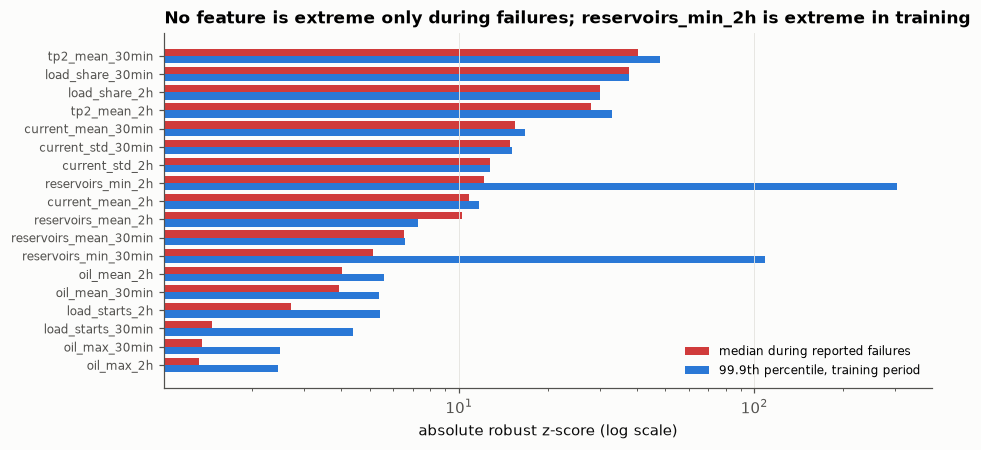

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2))
c = comparison.sort_values("median during failures")
y = np.arange(len(c))
ax.barh(y + 0.2, c["median during failures"], height=0.4, color=FAILURE, label="median during reported failures")
ax.barh(y - 0.2, c["99.9th percentile, training"], height=0.4, color=SERIES[0], label="99.9th percentile, training period")
ax.set_yticks(y, c.index, fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("absolute robust z-score (log scale)")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
ax.set_title("No feature is extreme only during failures; reservoirs_min_2h is extreme in training")
fig.savefig(FIG / "03_zscore_tails.png")
plt.show()

For each feature, the bar pairs compare how extreme it gets during failures with how extreme it already gets in normal training data. `reservoirs_min_2h` has a tiny typical spread (MAD ≈ 0.03 bar) but occasional deep pressure drops, for example when the train is put back into service, so its z-score reaches ~300 in training. The maximum over features inherits that tail: the calibrated threshold must sit above 200, far above the failure signal (median z of 10–40 on the informative features). Hotelling T² has the same weakness, because it assumes Gaussian features while several of them are heavy-tailed or discrete. Adding features to a distance-based score adds their noise too; a learned method will have to weigh them.

## 4. Following the drift

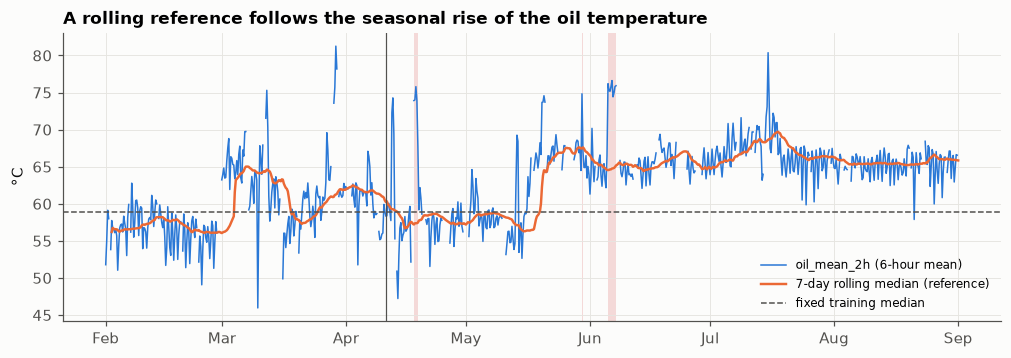

In [7]:
oil = X.oil_mean_2h
past = oil.shift(1).rolling("7D", min_periods=24 * 60)
baseline = past.median()
fig, ax = plt.subplots(figsize=(11, 3.4))
daily = oil.resample("6h").mean()
ax.plot(daily.index, daily, color=SERIES[0], lw=1, label="oil_mean_2h (6-hour mean)")
ax.plot(baseline.resample("6h").mean().index, baseline.resample("6h").mean(), color=SERIES[1], lw=1.6, label="7-day rolling median (reference)")
ax.axhline(ev.split(oil)[0].median(), color=INK_MUTED, ls="--", lw=1, label="fixed training median")
shade_failures(ax, FAILURES, label=False)
ax.axvline(ev.SPLIT, color=INK_MUTED, lw=0.8)
ax.set_ylabel("°C")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="lower right", fontsize=8)
ax.set_title("A rolling reference follows the seasonal rise of the oil temperature")
fig.savefig(FIG / "03_rolling_baseline.png")
plt.show()

In [8]:
fixed = ev.summarize({"oil_mean_2h, fixed training reference": oil,
                      "oil_mean_2h, 7-day rolling reference": scores["Rolling-baseline z, oil 2 h"]})
fixed[["detected", "false_alarms_per_week", "best_detected"]].round(2)

,detected,false_alarms_per_week,best_detected
detector,,,
"oil_mean_2h, fixed training reference",4,1.38,4.0
"oil_mean_2h, 7-day rolling reference",4,0.28,4.0


Same feature, same calibration rule, different reference: against the fixed February–April median, every warm summer day looks abnormal (1.38 false alarms per week); against the previous seven days, only sudden rises stand out (0.28). The price is that a slow fault developing over several days would be absorbed into the reference; air leaks develop in hours, which is why this works here.

## 5. Sensitivity to the chart parameters

For transparency only: the selection above used fixed textbook parameters. The table shows how the two best control charts react to other values. It is computed on the test period and is not used to pick a configuration.

In [9]:
sens = {}
for lam in [0.01, 0.02, 0.05, 0.1, 0.2]:
    sens[f"EWMA, motor current, λ={lam}"] = bl.ewma_chart(grid.Motor_current, grid_train.Motor_current, lam=lam)
for k in [0.25, 0.5, 1.0, 2.0]:
    sens[f"CUSUM, motor current, k={k}"] = bl.cusum(grid.Motor_current, grid_train.Motor_current, k=k)
sensitivity = ev.summarize(sens)
sensitivity[["detected", "lead_h_4", "false_alarms_per_week", "best_detected"]].round(2)

,detected,lead_h_4,false_alarms_per_week,best_detected
detector,,,,
"EWMA, motor current, λ=0.01",4,13.55,1.03,4.0
"EWMA, motor current, λ=0.02",4,13.27,0.71,4.0
"EWMA, motor current, λ=0.05",2,-0.32,0.06,4.0
"EWMA, motor current, λ=0.1",2,-0.15,0.32,4.0
"EWMA, motor current, λ=0.2",1,-0.13,0.26,3.0
"CUSUM, motor current, k=0.25",4,10.18,0.51,4.0
"CUSUM, motor current, k=0.5",4,12.88,0.64,4.0
"CUSUM, motor current, k=1.0",4,13.12,0.64,4.0
"CUSUM, motor current, k=2.0",1,-0.40,0.58,0.0


EWMA with the textbook λ = 0.05 lands on an unlucky point: 2/4 detected at its calibrated threshold, while λ = 0.01–0.02 (a memory of 2–3 hours) gives 4/4 with a 13-hour early warning on failure 4. A memory matched to the time scale of the fault matters more than the chart type. Choosing λ from this table would be tuning on the test period, so the benchmark keeps λ = 0.05; a validation period carved out of the training data would be the proper way to choose it.

## 6. The bar for machine learning

| Criterion | Best statistical result | Detector |
|---|---|---|
| Failures detected (calibrated) | 4/4 | several |
| False alarms per week at 4/4 | 0.28 | rolling-baseline z, oil 2 h |
| Early warning on failure 4 | 12.9 h | CUSUM, motor current |
| Simplicity | one feature, one threshold | sustained-load rule |

A learned method is worth deploying only if it beats the rolling-baseline oil score on false alarms while matching CUSUM on early warning, or brings something none of them has, such as explaining which signals deviate.